### MORF PacBio data processing - N14 three replicates are ones we end up using form benchmarking


#### Filter to retain only reads mapped to the forward strand
##### examples of input and output
- input morf.N0_R3.merged.sorted.bam
- output morf.N0_R3.merged.sorted_forward.bam

In [ ]:
import pysam
import os
from concurrent.futures import ThreadPoolExecutor, as_completed

# List of BAM files to process
bam_files = [
    "morf.N0_R1.merged.sorted.bam",
    "morf.N0_R2.merged.sorted.bam",
    "morf.N0_R3.merged.sorted.bam",
    "morf.N14_R1.merged.sorted.bam",
    "morf.N14_R2.merged.sorted.bam",
    "morf.N14_R3.merged.sorted.bam"
]

# Function to count primary aligned reads
def count_primary_aligned_reads(bam_file):
    count = 0
    with pysam.AlignmentFile(bam_file, "rb") as bam:
        for read in bam:
            if not read.is_secondary and not read.is_supplementary and not read.is_unmapped:
                count += 1
    return count

# Function to filter and retain reads mapped to the forward strand
def filter_forward_reads(bam_file):
    try:
        print(f"Starting processing of {bam_file}")
        base_name = os.path.splitext(bam_file)[0]
        filtered_bam_file = f"{base_name}_forward.bam"

        total_primary_reads = count_primary_aligned_reads(bam_file)
        print(f"{bam_file}: Total primary aligned reads before filtering = {total_primary_reads}")

        forward_primary_reads = 0

        with pysam.AlignmentFile(bam_file, "rb") as bam, \
             pysam.AlignmentFile(filtered_bam_file, "wb", template=bam) as filtered_bam:
            for read in bam:
                if not read.is_secondary and not read.is_supplementary and not read.is_unmapped:
                    if not read.is_reverse:
                        forward_primary_reads += 1
                        filtered_bam.write(read)

        print(f"{filtered_bam_file}: Total primary aligned reads after filtering = {forward_primary_reads}")
        return filtered_bam_file, forward_primary_reads
    except Exception as e:
        print(f"Error processing {bam_file}: {e}")
        raise

# Main function to process all BAM files in parallel
def main():
    with ThreadPoolExecutor() as executor:
        futures = {executor.submit(filter_forward_reads, bam_file): bam_file for bam_file in bam_files}
        for future in as_completed(futures):
            bam_file = futures[future]
            try:
                filtered_bam_file, forward_primary_reads = future.result()
                print(f"{filtered_bam_file}: Primary aligned reads = {forward_primary_reads}")
            except Exception as exc:
                print(f"{bam_file} generated an exception: {exc}")

if __name__ == "__main__":
    main()

#### Filter to retain only reads mapped to the last base of the reference
##### examples of input and output
- input morf.N0_R1.merged.sorted_forward.bam
- output morf.N14_R1.filtered.soft_clipped.sorted.bam

##### during processing, there are two tags added for downstream analysis
- TN: transcript name, the ground truth which transcript the reads come from
- UI: UMI, 

In [ ]:
import pysam
import concurrent.futures
import os

def create_transcript_id_mapping(lookup_table_file):
    with open(lookup_table_file) as f:
        return {line.strip().split()[0]: line.strip().split()[1] for line in f}

def process_read(read, matching_reads, non_matching_reads, ref_lengths):
    if read.is_unmapped or not read.cigartuples:
        non_matching_reads.append(read)
    else:
        # Check if the read's alignment includes the last base of the reference sequence
        ref_end = read.reference_end
        ref_name = read.reference_name
        ref_length = ref_lengths[ref_name]
        if ref_end == ref_length:
            # Set TN tag as the reference name
            read.set_tag('TN', ref_name)
            # Extract the last 14 bases and set UI tag
            if len(read.query_sequence) >= 14:
                ui_tag = read.query_sequence[-14:]
                read.set_tag('UI', ui_tag)
            matching_reads.append(read)
        else:
            non_matching_reads.append(read)

def process_reads_with_end_alignment_check_multithread(bam_file, matching_reads, non_matching_reads, num_threads=4):
    with pysam.AlignmentFile(bam_file, "rb") as infile:
        ref_lengths = {ref: infile.get_reference_length(ref) for ref in infile.references}
        with concurrent.futures.ThreadPoolExecutor(max_workers=num_threads) as executor:
            futures = [executor.submit(process_read, read, matching_reads, non_matching_reads, ref_lengths) for read in infile.fetch()]
            for future in concurrent.futures.as_completed(futures):
                future.result()

def trim_read(read):
    if read.is_unmapped or not read.cigartuples or read.query_qualities is None:
        return None

    # Remove soft-clipping from the beginning of the read
    while read.cigartuples and read.cigartuples[0][0] == 4:
        read.query_sequence = read.query_sequence[read.cigartuples[0][1]:]
        if read.query_qualities is not None:
            read.query_qualities = read.query_qualities[read.cigartuples[0][1]:]
        read.cigartuples = read.cigartuples[1:]
    # Remove soft-clipping from the end of the read
    while read.cigartuples and read.cigartuples[-1][0] == 4:
        read.query_sequence = read.query_sequence[:-read.cigartuples[-1][1]]
        if read.query_qualities is not None:
            read.query_qualities = read.query_qualities[:-read.cigartuples[-1][1]]
        read.cigartuples = read.cigartuples[:-1]
    return read

def trim_based_on_cigar(matching_reads, soft_clipped_reads, thread_number):
    with concurrent.futures.ThreadPoolExecutor(max_workers=thread_number) as executor:
        futures = [executor.submit(trim_read, read) for read in matching_reads]
        for future in concurrent.futures.as_completed(futures):
            trimmed_read = future.result()
            if trimmed_read:
                soft_clipped_reads.append(trimmed_read)

def count_primary_alignments(bam_file):
    with pysam.AlignmentFile(bam_file, "rb") as file:
        return sum(1 for read in file.fetch() if not read.is_secondary and not read.is_supplementary)

def process_bam_file(bam_file, thread_number):
    sorted_output_file = bam_file.replace(".merged.sorted_forward.bam", ".last_base_filtered.withTN_UI.soft_clipped.sorted.bam")

    if not os.path.exists(bam_file) or os.path.getsize(bam_file) == 0:
        raise ValueError(f"The file {bam_file} does not exist or is empty")

    pysam.index(bam_file)

    matching_reads = []
    non_matching_reads = []
    process_reads_with_end_alignment_check_multithread(bam_file, matching_reads, non_matching_reads, thread_number)

    soft_clipped_reads = []
    trim_based_on_cigar(matching_reads, soft_clipped_reads, thread_number)

    with pysam.AlignmentFile(sorted_output_file, "wb", header=pysam.AlignmentFile(bam_file, "rb").header) as outfile:
        for read in soft_clipped_reads:
            outfile.write(read)

    # Sort the output file
    pysam.sort("-o", sorted_output_file, sorted_output_file)

    # Index the sorted output file
    pysam.index(sorted_output_file)

    print(f"Number of primary alignments in {bam_file}: {count_primary_alignments(bam_file)}")
    print(f"Number of primary alignments in intermediate non-matching reads: {len(non_matching_reads)}")
    print(f"Number of primary alignments in intermediate matching reads: {len(matching_reads)}")
    print(f"Number of primary alignments in {sorted_output_file}: {count_primary_alignments(sorted_output_file)}")

def main():
    bam_files = [
        "morf.N0_R1.merged.sorted_forward.bam",
        "morf.N0_R2.merged.sorted_forward.bam",
        "morf.N0_R3.merged.sorted_forward.bam",
        "morf.N14_R1.merged.sorted_forward.bam",
        "morf.N14_R2.merged.sorted_forward.bam",
        "morf.N14_R3.merged.sorted_forward.bam"
    ]
    thread_number = 16

    for bam_file in bam_files:
        process_bam_file(bam_file, thread_number)

if __name__ == "__main__":
    main()

#### Generate count matrix based on TN tag for non-deup bams
##### we generated two versions
- one with transcript name for further barcode quantification comparison
- one with Gencode IDs for LRAA benchmarking

In [ ]:
import pysam
import pandas as pd
from collections import defaultdict

def extract_tn_counts(bam_file):
    tn_counts = defaultdict(int)
    with pysam.AlignmentFile(bam_file, "rb") as bam:
        for read in bam.fetch():
            if read.has_tag('TN'):
                tn_tag = read.get_tag('TN')
                tn_counts[tn_tag] += 1
    return tn_counts

def generate_count_matrix(bam_files, output_file):
    all_tn_counts = defaultdict(dict)
    
    for bam_file in bam_files:
        # Extract sample name from the BAM file name and format it
        sample_name = bam_file.split('.')[1] + "_" + bam_file.split('.')[2] + "_non_dedup"
        tn_counts = extract_tn_counts(bam_file)
        for tn_tag, count in tn_counts.items():
            all_tn_counts[tn_tag][sample_name] = count
    
    # Convert the dictionary to a DataFrame
    df = pd.DataFrame.from_dict(all_tn_counts, orient='index').fillna(0).astype(int)
    df.index.name = 'TN'
    df.to_csv(output_file)

def map_tn_to_transcript_id(count_matrix_file, transfer_table_file, output_file):
    # Read the count matrix CSV file
    count_matrix_df = pd.read_csv(count_matrix_file)

    # Read the transfer table TSV file
    transfer_table_df = pd.read_csv(transfer_table_file, sep='\t')

    # Ensure the transfer table has the correct column names
    if len(transfer_table_df.columns) == 3:
        transfer_table_df.columns = ['Index', 'transcript_name', 'transcript_id']
    elif len(transfer_table_df.columns) == 2:
        transfer_table_df.columns = ['transcript_name', 'transcript_id']

    # Drop the first row if it contains column names
    if transfer_table_df.iloc[0]['transcript_name'] == 'transcript_name':
        transfer_table_df = transfer_table_df.drop(0)

    # Create a dictionary for TN to transcript_id mapping
    tn_to_transcript_id = dict(zip(transfer_table_df['transcript_name'], transfer_table_df['transcript_id']))

    # Print the total number of rows before the transfer
    print(f"Total number of rows before transfer: {len(count_matrix_df)}")

    # Replace TN tags with transcript_id in the count matrix
    count_matrix_df['transcript_id'] = count_matrix_df['TN'].map(tn_to_transcript_id)

    # Print the number of unique transcript_id after mapping
    unique_transcript_ids = count_matrix_df['transcript_id'].nunique()
    print(f"Number of unique transcript_id after mapping: {unique_transcript_ids}")

    # Save the updated count matrix to a new CSV file
    count_matrix_df.to_csv(output_file, index=False)
    print(f"Updated count matrix saved to {output_file}")

# List of BAM files
bam_files = [
    "morf.N0_R1.last_base_filtered.withTN_UI.soft_clipped.sorted.bam",
    "morf.N0_R2.last_base_filtered.withTN_UI.soft_clipped.sorted.bam",
    "morf.N0_R3.last_base_filtered.withTN_UI.soft_clipped.sorted.bam",
    "morf.N14_R1.last_base_filtered.withTN_UI.soft_clipped.sorted.bam",
    "morf.N14_R2.last_base_filtered.withTN_UI.soft_clipped.sorted.bam",
    "morf.N14_R3.last_base_filtered.withTN_UI.soft_clipped.sorted.bam"
]

# Generate count matrix for all files
generate_count_matrix(bam_files, "morf.N0_N14_before_dedup_count_matrix_with_gene_name.csv")

# Map TN to transcript_id and save the updated count matrix
map_tn_to_transcript_id(
    "morf.N0_N14_before_dedup_count_matrix_with_gene_name.csv",
    "transfer_table.tsv",
    "morf.N0_N14_before_dedup_count_matrix_with_gencode_name.csv"
)

#### Dedup UMI

In [ ]:
import pysam
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from collections import defaultdict

def extract_ui_tn_pairs(bam_file):
    ui_tn_counts = defaultdict(int)
    with pysam.AlignmentFile(bam_file, "rb") as bam:
        for read in bam.fetch():
            if read.has_tag('UI') and read.has_tag('TN'):
                ui_tag = read.get_tag('UI')
                tn_tag = read.get_tag('TN')
                ui_tn_pair = (ui_tag, tn_tag)
                ui_tn_counts[ui_tn_pair] += 1
    return ui_tn_counts

def save_ui_tn_frequencies(ui_tn_counts, output_file):
    df = pd.DataFrame(list(ui_tn_counts.items()), columns=['UI_TN', 'Frequency'])
    df[['UI', 'TN']] = pd.DataFrame(df['UI_TN'].tolist(), index=df.index)
    df = df[['UI', 'TN', 'Frequency']]
    df.to_csv(output_file, sep='\t', index=False)

def plot_ui_tn_frequencies(ui_tn_counts, output_file):
    frequencies = list(ui_tn_counts.values())
    bins = np.logspace(0, np.log10(max(frequencies)), num=50)
    hist, bin_edges = np.histogram(frequencies, bins=bins)
    
    # Calculate the midpoints of the bins for plotting
    bin_midpoints = (bin_edges[:-1] + bin_edges[1:]) / 2
    
    plt.figure(figsize=(10, 6))
    plt.scatter(np.log10(bin_midpoints), np.log10(hist), marker='o')
    plt.xlabel('Barcode Frequency Bin (log10)')
    plt.ylabel('Occurrence of Unique Barcode (log10)')
    plt.title('Frequency of UMI Events')
    plt.grid(True)
    plt.savefig(output_file)
    plt.close()

def dedup_umi(bam_file, output_file):
    ui_tn_seen = set()
    with pysam.AlignmentFile(bam_file, "rb") as bam_in, pysam.AlignmentFile(output_file, "wb", header=bam_in.header) as bam_out:
        for read in bam_in.fetch():
            if read.has_tag('UI') and read.has_tag('TN'):
                ui_tag = read.get_tag('UI')
                tn_tag = read.get_tag('TN')
                ui_tn_pair = (ui_tag, tn_tag)
                if ui_tn_pair not in ui_tn_seen:
                    bam_out.write(read)
                    ui_tn_seen.add(ui_tn_pair)

def count_primary_alignments(bam_file):
    count = 0
    with pysam.AlignmentFile(bam_file, "rb") as bam:
        for read in bam.fetch():
            if not read.is_secondary and not read.is_supplementary:
                count += 1
    return count

def index_bam_file(bam_file):
    pysam.index(bam_file)

# List of BAM files
bam_files = [
    "morf.N14_R1.last_base_filtered.withTN_UI.soft_clipped.sorted.bam",
    "morf.N14_R2.last_base_filtered.withTN_UI.soft_clipped.sorted.bam",
    "morf.N14_R3.last_base_filtered.withTN_UI.soft_clipped.sorted.bam"
]

# Store primary alignment counts for plotting
primary_alignments_counts = []

# Process each BAM file
for bam_file in bam_files:
    # Index the BAM file
    index_bam_file(bam_file)
    
    # Extract UI-TN pairs and their frequencies
    ui_tn_counts = extract_ui_tn_pairs(bam_file)
    
    # Save UI-TN frequencies to TSV file
    tsv_output_file = bam_file.replace('.bam', '_ui_tn_frequencies.tsv')
    save_ui_tn_frequencies(ui_tn_counts, tsv_output_file)
    
    # Plot UI-TN frequencies
    plot_output_file = bam_file.replace('.bam', '_ui_tn_frequencies_plot.png')
    plot_ui_tn_frequencies(ui_tn_counts, plot_output_file)
    
    # Count primary alignments before deduplication
    primary_alignments_before = count_primary_alignments(bam_file)
    print(f"Number of primary alignments before UMI deduplication for {bam_file}: {primary_alignments_before}")
    
    # Deduplicate UMI
    dedup_bam_file = bam_file.replace('.bam', '_dedup.bam')
    dedup_umi(bam_file, dedup_bam_file)
    
    # Index the deduplicated BAM file
    index_bam_file(dedup_bam_file)
    
    # Count primary alignments after deduplication
    primary_alignments_after = count_primary_alignments(dedup_bam_file)
    print(f"Number of primary alignments after UMI deduplication for {dedup_bam_file}: {primary_alignments_after}")
    
    # Store the counts for plotting
    primary_alignments_counts.append((bam_file, primary_alignments_before, primary_alignments_after))

# Plot primary alignments before and after deduplication for all files
labels = [bam_file.split('.')[1] for bam_file, _, _ in primary_alignments_counts]
before_counts = [before for _, before, _ in primary_alignments_counts]
after_counts = [after for _, _, after in primary_alignments_counts]

x = np.arange(len(labels))  # the label locations
width = 0.35  # the width of the bars

fig, ax = plt.subplots(figsize=(10, 6))
rects1 = ax.bar(x - width/2, before_counts, width, label='Before Deduplication')
rects2 = ax.bar(x + width/2, after_counts, width, label='After Deduplication')

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_xlabel('BAM Files')
ax.set_ylabel('Number of Primary Alignments')
ax.set_title('Primary Alignments Before and After UMI Deduplication')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()

fig.tight_layout()
plt.grid(True)
plt.savefig('morf.N14.last_base_filtered.withTN_UI.soft_clipped.sorted.primary_alignments_before_after_deduplication.png')
plt.close()

#### Generate count matrix based on TN tag for postdedup bams
##### we generated two versions
- one with transcript name for further barcode quantification comparison
- one with Gencode IDs for LRAA benchmarking

In [ ]:
def generate_count_matrix(bam_files, output_file):
    all_tn_counts = defaultdict(dict)
    
    for bam_file in bam_files:
        # Extract sample name from the BAM file name and format it
        sample_name = bam_file.split('.')[1] + "_" + bam_file.split('.')[2] + "_post_dedup"
        tn_counts = extract_tn_counts(bam_file)
        for tn_tag, count in tn_counts.items():
            all_tn_counts[tn_tag][sample_name] = count
    
    # Convert the dictionary to a DataFrame
    df = pd.DataFrame.from_dict(all_tn_counts, orient='index').fillna(0).astype(int)
    df.index.name = 'TN'
    df.to_csv(output_file)


# List of BAM files for the second set
bam_files_set2 = [
    "morf.N14_R1.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.bam",
    "morf.N14_R2.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.bam",
    "morf.N14_R3.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.bam"
]

# Generate count matrix for the second set of files
generate_count_matrix(bam_files_set2, "morf.N14_dedup_count_matrix_with_gene_name.csv")

# Map TN to transcript_id and save the updated count matrix for the second set
map_tn_to_transcript_id(
    "morf.N14_dedup_count_matrix_with_gene_name.csv",
    "transfer_table.tsv",
    "morf.N14_dedup_count_matrix_with_gencode_name.csv"
)

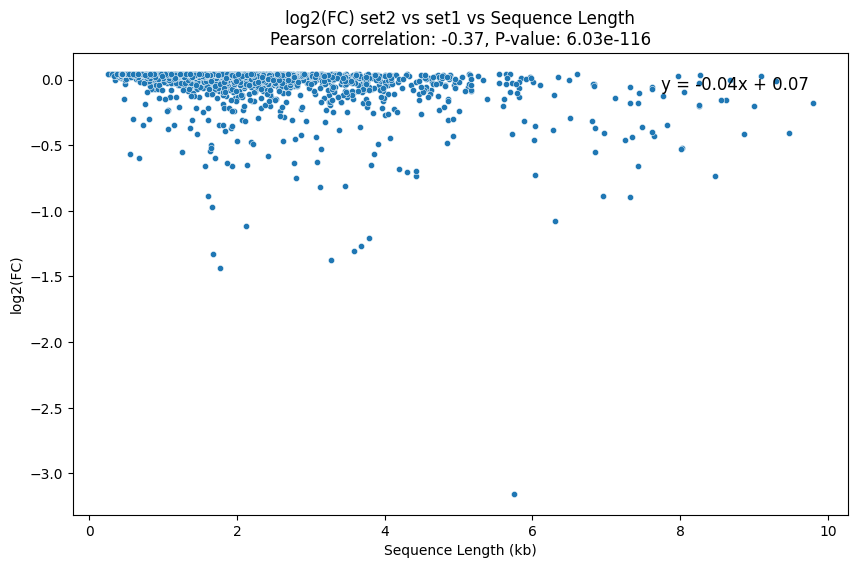

/opt/conda/lib/python3.10/site-packages/pandas/core/arraylike.py:396: RuntimeWarning: divide by zero encountered in log2
  result = getattr(ufunc, method)(*inputs, **kwargs)


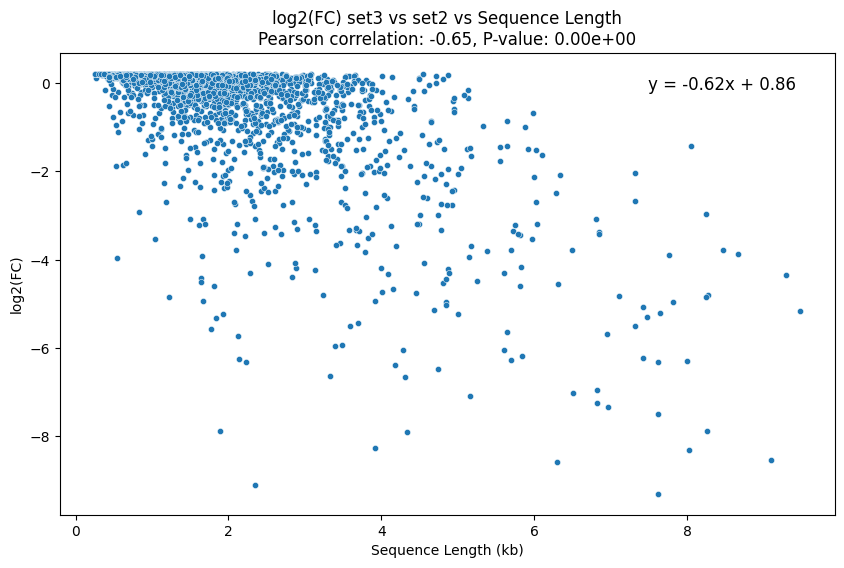

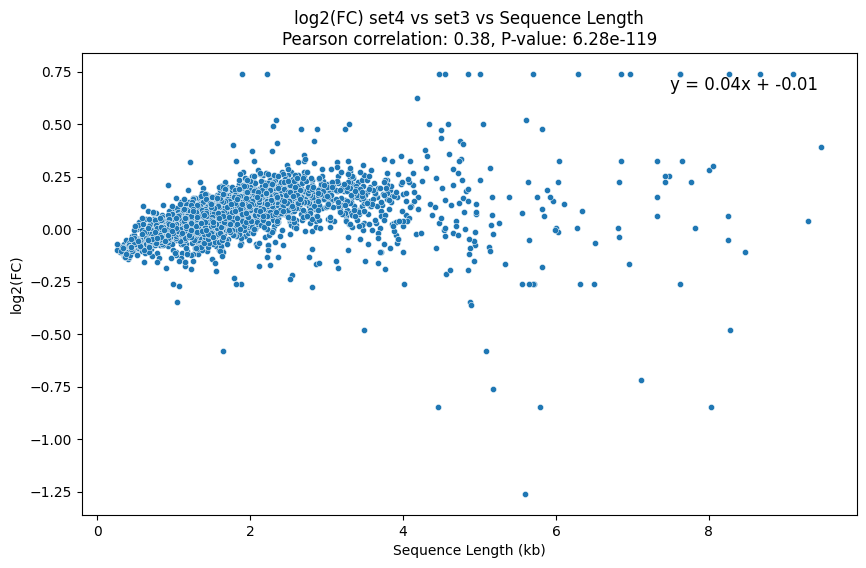

/opt/conda/lib/python3.10/site-packages/pandas/core/arraylike.py:396: RuntimeWarning: divide by zero encountered in log2
  result = getattr(ufunc, method)(*inputs, **kwargs)


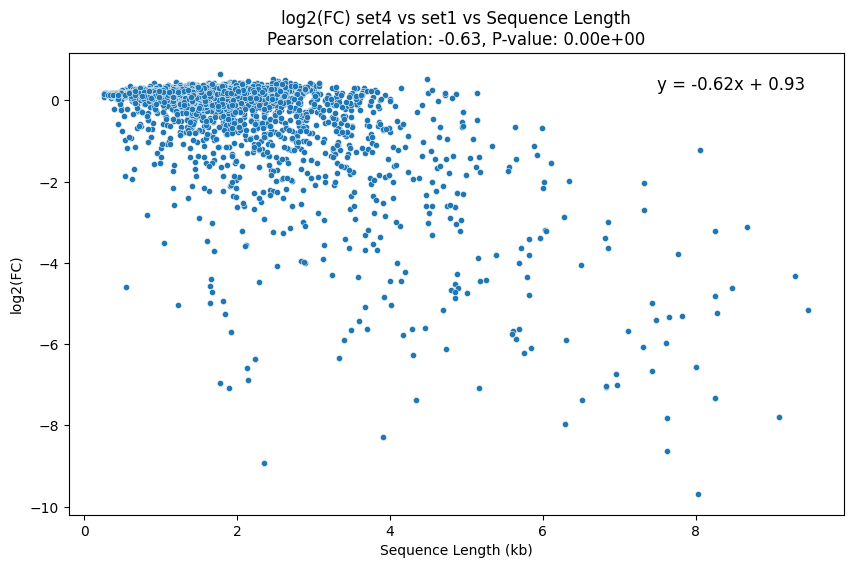

In [17]:
import pandas as pd
import pysam
from Bio import SeqIO
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import pearsonr
import statsmodels.api as sm

# Function to extract read counts from BAM files
def extract_read_counts(bam_files):
    reference_counts = {}
    for bam_file in bam_files:
        with pysam.AlignmentFile(bam_file, "rb") as bam:
            for read in bam.fetch():
                if not read.is_secondary and not read.is_supplementary and not read.is_unmapped:
                    reference_name = bam.get_reference_name(read.reference_id)
                    if reference_name in reference_counts:
                        reference_counts[reference_name] += 1
                    else:
                        reference_counts[reference_name] = 1
    return reference_counts

# Function to normalize counts by TPM
def normalize_by_tpm(counts):
    total_counts = counts.sum()
    tpm = (counts / total_counts) * 1e6
    return tpm

# Function to extract sequence lengths from FASTA file
def extract_sequence_lengths(fasta_file):
    sequences = {record.id: len(record.seq) for record in SeqIO.parse(fasta_file, "fasta")}
    return sequences

# Function to calculate fold change and plot log2(FC) vs sequence length
def plot_logfc_vs_seq_length(merged_df, output_plot, comparison_name):
    # Calculate log2(FC)
    merged_df['log2FC'] = np.log2(merged_df['FC'])
    
    # Filter out -inf and NaN values
    filtered_df = merged_df.replace([np.inf, -np.inf], np.nan).dropna(subset=['log2FC'])
    
    # Calculate Pearson correlation coefficient and p-value
    pearson_corr, p_value = pearsonr(filtered_df['SeqLength_kb'], filtered_df['log2FC'])
    
    # Fit linear model
    X = sm.add_constant(filtered_df['SeqLength_kb'])
    model = sm.OLS(filtered_df['log2FC'], X).fit()
    intercept, slope = model.params
    equation = f'y = {slope:.2f}x + {intercept:.2f}'
    
    # Plot log2(FC) as a function of sequence length in kb
    plt.figure(figsize=(10, 6))
    sns.scatterplot(x='SeqLength_kb', y='log2FC', data=filtered_df, s=20)
    plt.title(f'log2(FC) {comparison_name} vs Sequence Length\nPearson correlation: {pearson_corr:.2f}, P-value: {p_value:.2e}')
    plt.xlabel('Sequence Length (kb)')
    plt.ylabel('log2(FC)')
    plt.text(0.95, 0.95, equation, transform=plt.gca().transAxes, fontsize=12, verticalalignment='top', horizontalalignment='right')
    plt.savefig(output_plot)
    plt.show()

def main():
    # Define BAM file sets
    bam_sets = {
        "set1": [
            "morf.N14_R1.merged.sorted.bam",
            "morf.N14_R2.merged.sorted.bam",
            "morf.N14_R3.merged.sorted.bam"
        ],
        "set2": [
            "morf.N14_R1.merged.sorted_forward.bam",
            "morf.N14_R2.merged.sorted_forward.bam",
            "morf.N14_R3.merged.sorted_forward.bam"
        ],
        "set3": [
            "morf.N14_R1.last_base_filtered.withTN_UI.soft_clipped.sorted.bam",
            "morf.N14_R2.last_base_filtered.withTN_UI.soft_clipped.sorted.bam",
            "morf.N14_R3.last_base_filtered.withTN_UI.soft_clipped.sorted.bam"
        ],
        "set4": [
            "morf.N14_R1.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.bam",
            "morf.N14_R2.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.bam",
            "morf.N14_R3.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.bam"
        ]
    }

    # Extract read counts for each set
    counts = {}
    for set_name, bam_files in bam_sets.items():
        counts[set_name] = extract_read_counts(bam_files)

    # Convert counts to DataFrame
    counts_df = pd.DataFrame(counts).fillna(0)

    # Normalize counts by TPM
    for set_name in bam_sets.keys():
        counts_df[f'TPM_{set_name}'] = normalize_by_tpm(counts_df[set_name])

    # Calculate average TPM for each set
    for set_name in bam_sets.keys():
        counts_df[f'Avg_TPM_{set_name}'] = counts_df[[f'TPM_{set_name}']].mean(axis=1)

    # Extract sequence lengths from FASTA file
    fasta_file = "morf_insert.fasta"
    sequence_lengths = extract_sequence_lengths(fasta_file)
    counts_df['SeqLength'] = counts_df.index.map(sequence_lengths)
    counts_df['SeqLength_kb'] = counts_df['SeqLength'] / 1000

    # Define comparisons
    comparisons = [
        ("set2", "set1"),
        ("set3", "set2"),
        ("set4", "set3"),
        ("set4", "set1")
    ]

    # Calculate fold change and plot log2(FC) vs sequence length for each comparison
    for set_a, set_b in comparisons:
        counts_df['FC'] = counts_df[f'Avg_TPM_{set_a}'] / counts_df[f'Avg_TPM_{set_b}']
        output_plot = f"log2FC_{set_a}_vs_{set_b}.png"
        plot_logfc_vs_seq_length(counts_df, output_plot, f'{set_a} vs {set_b}')

if __name__ == "__main__":
    main()

Total reads in morf.set2.lima1.bc03_5p--3p.bam: 4949809
Total reads in morf.set2.lima1.bc02_5p--3p.bam: 5002014
Total reads in morf.set2.lima2.bc03_5p--3p.bam: 5160734
Total reads in morf.set2.lima1.bc01_5p--3p.bam: 5189782
Total reads in morf.set2.lima2.bc02_5p--3p.bam: 5209463
Total reads in morf.set2.lima2.bc01_5p--3p.bam: 5411713
Total reads in morf.set2.lima1.bc03_5p--3p.bam: 4949809
Total reads in morf.set2.lima1.bc02_5p--3p.bam: 5002014
Total reads in morf.set2.lima1.bc06_5p--3p.bam: 6455977
Total reads in morf.set2.lima2.bc03_5p--3p.bam: 5160734
Total reads in morf.set2.lima1.bc05_5p--3p.bam: 6634394
Total reads in morf.set2.lima1.bc01_5p--3p.bam: 5189782
Total reads for N0_R1 in set0: 5189782
Total reads in morf.set2.lima2.bc02_5p--3p.bam: 5209463
Total reads in morf.set2.lima1.bc04_5p--3p.bam: 6658957
Total reads in morf.set2.lima2.bc06_5p--3p.bam: 6758064
Total reads in morf.set2.lima2.bc01_5p--3p.bam: 5411713
Total reads for N0_R1 in set0: 10601495
Total reads for N0_R2 in 

<Figure size 1200x800 with 0 Axes>

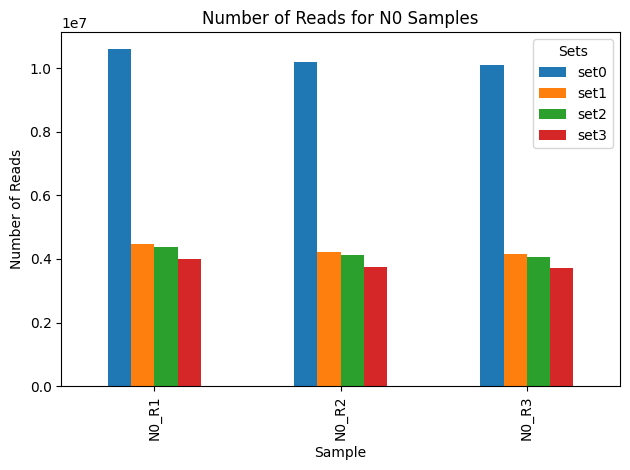

<Figure size 1200x800 with 0 Axes>

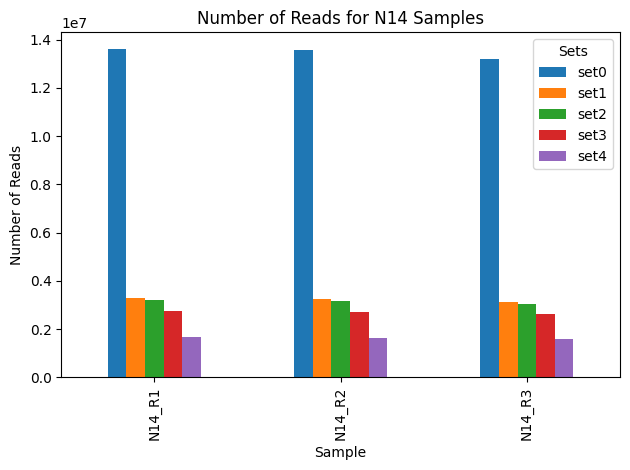

In [2]:
import pandas as pd
import pysam
from Bio import SeqIO
import matplotlib.pyplot as plt
import os
from concurrent.futures import ThreadPoolExecutor

# Function to index BAM files if not already indexed
def index_bam_files(bam_files):
    for bam_file in bam_files:
        if not os.path.exists(bam_file + ".bai"):
            pysam.index(bam_file)

# Function to extract total read counts from BAM files
def extract_total_read_counts(bam_file, count_unmapped=False):
    count = 0
    if count_unmapped:
        with pysam.AlignmentFile(bam_file, "rb", check_sq=False) as bam:
            for read in bam.fetch(until_eof=True):
                count += 1
    else:
        with pysam.AlignmentFile(bam_file, "rb", check_sq=False) as bam:
            for read in bam.fetch():
                if not read.is_secondary and not read.is_supplementary and not read.is_unmapped:
                    count += 1

    print(f"Total reads in {bam_file}: {count}")
    return count

# Function to extract read counts from FASTA files
def extract_read_counts_from_fasta(fasta_files):
    reference_counts = {}
    for fasta_file in fasta_files:
        count = sum(1 for _ in SeqIO.parse(fasta_file, "fasta"))
        reference_counts[fasta_file] = count
    return reference_counts

def main():
    # Define BAM file sets
    bam_sets = {
        "set1": [
            "morf.N0_R1.merged.sorted.bam",
            "morf.N0_R2.merged.sorted.bam",
            "morf.N0_R3.merged.sorted.bam",
            "morf.N14_R1.merged.sorted.bam",
            "morf.N14_R2.merged.sorted.bam",
            "morf.N14_R3.merged.sorted.bam"
        ],
        "set2": [
            "morf.N0_R1.merged.sorted_forward.bam",
            "morf.N0_R2.merged.sorted_forward.bam",
            "morf.N0_R3.merged.sorted_forward.bam",
            "morf.N14_R1.merged.sorted_forward.bam",
            "morf.N14_R2.merged.sorted_forward.bam",
            "morf.N14_R3.merged.sorted_forward.bam"
        ],
        "set3": [
            "morf.N0_R1.last_base_filtered.withTN_UI.soft_clipped.sorted.bam",
            "morf.N0_R2.last_base_filtered.withTN_UI.soft_clipped.sorted.bam",
            "morf.N0_R3.last_base_filtered.withTN_UI.soft_clipped.sorted.bam",
            "morf.N14_R1.last_base_filtered.withTN_UI.soft_clipped.sorted.bam",
            "morf.N14_R2.last_base_filtered.withTN_UI.soft_clipped.sorted.bam",
            "morf.N14_R3.last_base_filtered.withTN_UI.soft_clipped.sorted.bam"
        ],
        "set4": [
            "morf.N14_R1.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.bam",
            "morf.N14_R2.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.bam",
            "morf.N14_R3.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.bam"
        ]
    }

    # Define BAM files for set0
    bam_files_set0 = {
        "N0_R1": [
            "morf.set2.lima1.bc01_5p--3p.bam",
            "morf.set2.lima2.bc01_5p--3p.bam"
        ],
        "N0_R2": [
            "morf.set2.lima1.bc02_5p--3p.bam",
            "morf.set2.lima2.bc02_5p--3p.bam"
        ],
        "N0_R3": [
            "morf.set2.lima1.bc03_5p--3p.bam",
            "morf.set2.lima2.bc03_5p--3p.bam"
        ],
        "N14_R1": [
            "morf.set2.lima1.bc04_5p--3p.bam",
            "morf.set2.lima2.bc04_5p--3p.bam"
        ],
        "N14_R2": [
            "morf.set2.lima1.bc05_5p--3p.bam",
            "morf.set2.lima2.bc05_5p--3p.bam"
        ],
        "N14_R3": [
            "morf.set2.lima1.bc06_5p--3p.bam",
            "morf.set2.lima2.bc06_5p--3p.bam"
        ]
    }

    # Index BAM files
    for bam_files in bam_files_set0.values():
        index_bam_files(bam_files)
    for bam_files in bam_sets.values():
        index_bam_files(bam_files)

    # Extract read counts for set0 using parallel processing
    counts_set0 = {sample: {} for sample in bam_files_set0.keys()}
    with ThreadPoolExecutor(max_workers=16) as executor:
        futures = {executor.submit(extract_total_read_counts, bam_file, True): (sample, "set0") for sample, bam_files in bam_files_set0.items() for bam_file in bam_files}
        for future in futures:
            sample, set_name = futures[future]
            if set_name not in counts_set0[sample]:
                counts_set0[sample][set_name] = 0
            counts_set0[sample][set_name] += future.result()
            print(f"Total reads for {sample} in set0: {counts_set0[sample][set_name]}")

    # Extract read counts for other sets using parallel processing
    counts_other_sets = {sample: {} for sample in ["N0_R1", "N0_R2", "N0_R3", "N14_R1", "N14_R2", "N14_R3"]}
    with ThreadPoolExecutor(max_workers=16) as executor:
        futures = {executor.submit(extract_total_read_counts, bam_file, False): (sample, set_name) for set_name, bam_files in bam_sets.items() for sample, bam_file in zip(["N0_R1", "N0_R2", "N0_R3", "N14_R1", "N14_R2", "N14_R3"], bam_files)}
        for future in futures:
            sample, set_name = futures[future]
            if set_name not in counts_other_sets[sample]:
                counts_other_sets[sample][set_name] = 0
            counts_other_sets[sample][set_name] += future.result()

    # Correctly assign set4 counts to N14 samples
    for i, sample in enumerate(["N14_R1", "N14_R2", "N14_R3"]):
        counts_other_sets[sample]["set4"] = extract_total_read_counts(bam_sets["set4"][i], False)

    # Combine counts
    counts = {sample: {**counts_set0.get(sample, {}), **counts_other_sets.get(sample, {})} for sample in set(counts_set0) | set(counts_other_sets)}

    # Debug print to check the counts
    print("Counts Set0:", counts_set0)
    print("Counts Other Sets:", counts_other_sets)
    print("Combined Counts:", counts)

    # Convert counts to DataFrame
    counts_df = pd.DataFrame.from_dict(counts, orient='index').fillna(0)

    # Save counts to TSV file
    counts_df.to_csv('read_counts_summary.tsv', sep='\t')

    # Plot number of reads for N0 samples
    plt.figure(figsize=(12, 8))
    counts_df.loc[['N0_R1', 'N0_R2', 'N0_R3'], ['set0', 'set1', 'set2', 'set3']].plot(kind='bar')
    plt.title('Number of Reads for N0 Samples')
    plt.xlabel('Sample')
    plt.ylabel('Number of Reads')
    plt.legend(title='Sets')
    plt.tight_layout()
    plt.savefig('number_of_reads_N0_samples.png')
    plt.show()

    # Plot number of reads for N14 samples
    plt.figure(figsize=(12, 8))
    counts_df.loc[['N14_R1', 'N14_R2', 'N14_R3'], ['set0', 'set1', 'set2', 'set3', 'set4']].plot(kind='bar')
    plt.title('Number of Reads for N14 Samples')
    plt.xlabel('Sample')
    plt.ylabel('Number of Reads')
    plt.legend(title='Sets')
    plt.tight_layout()
    plt.savefig('number_of_reads_N14_samples.png')
    plt.show()

if __name__ == "__main__":
    main()

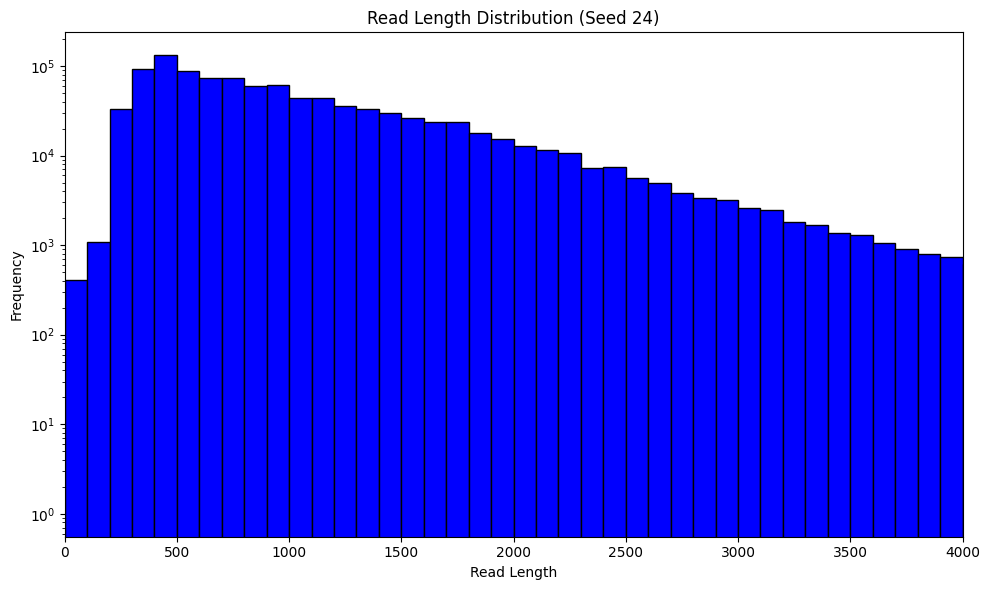

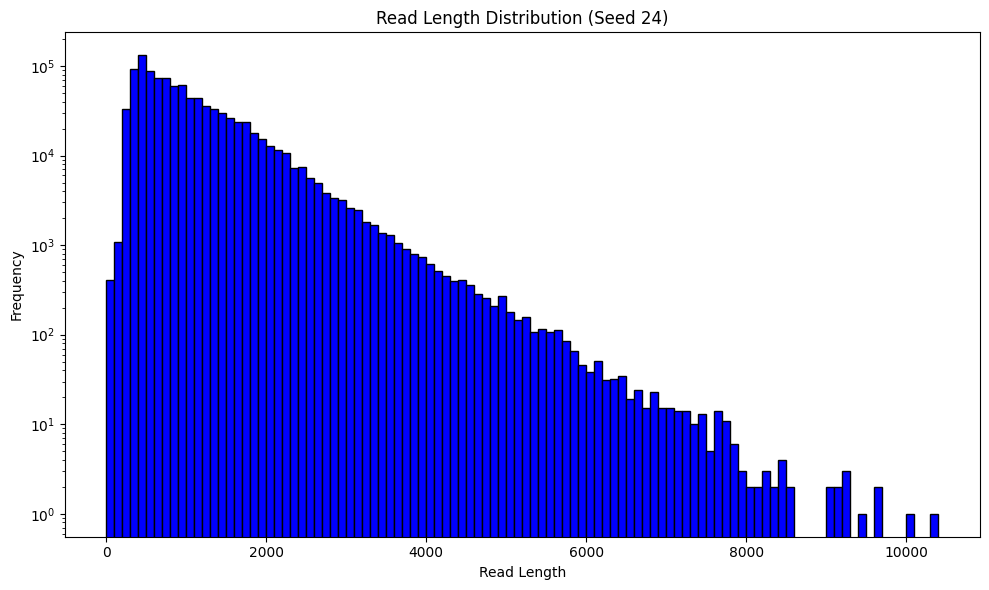

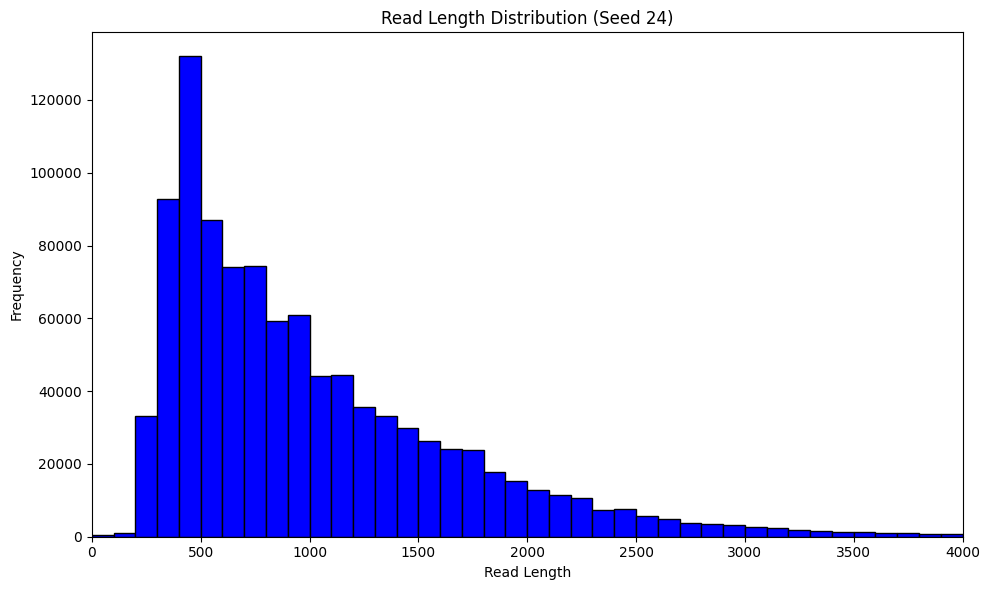

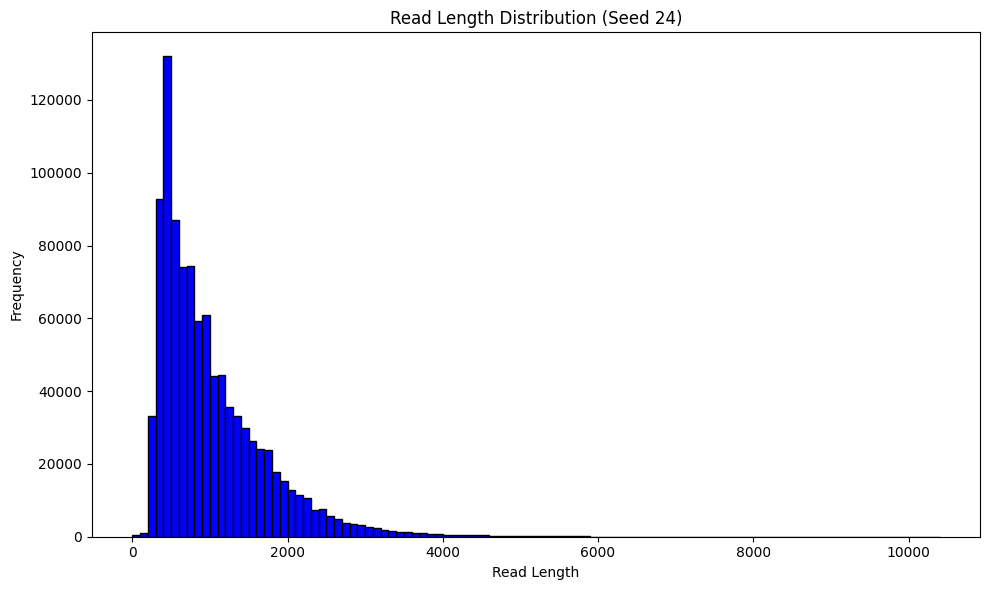

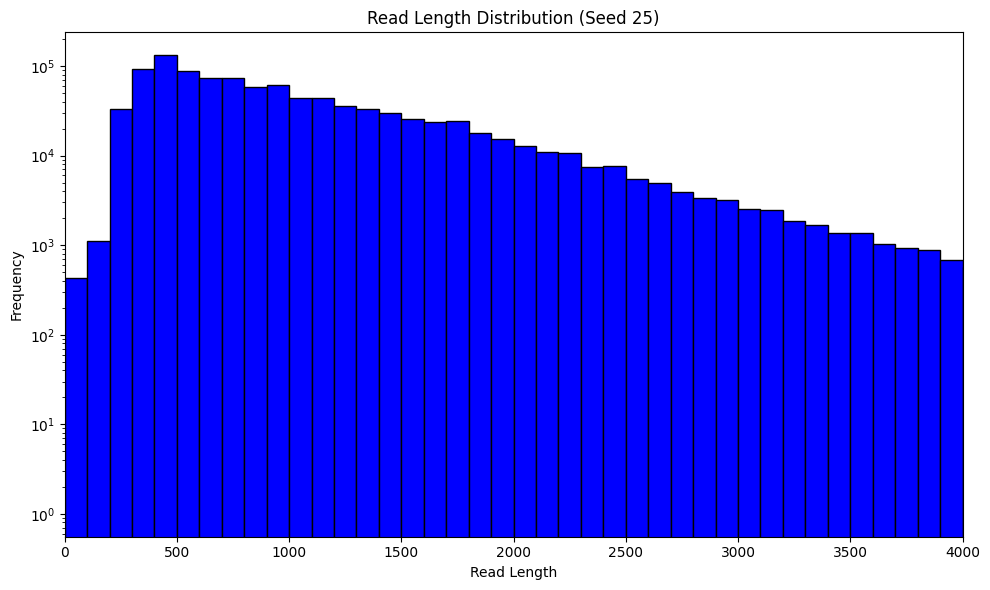

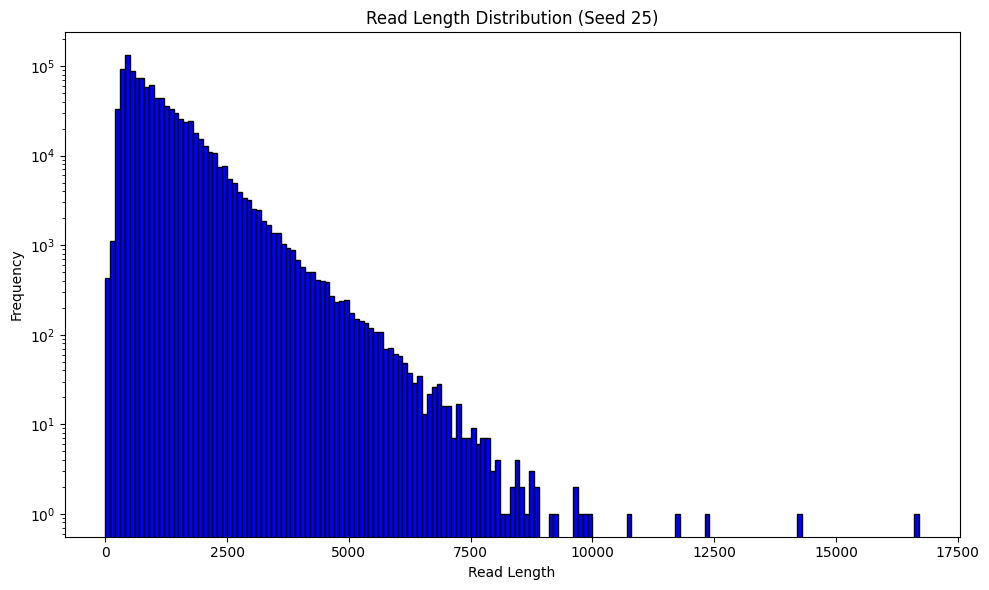

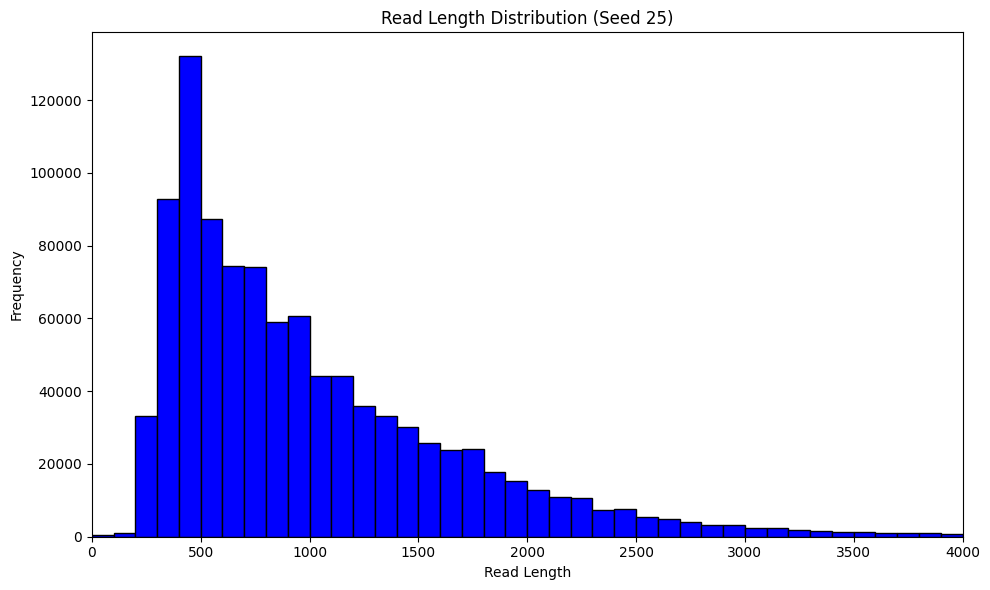

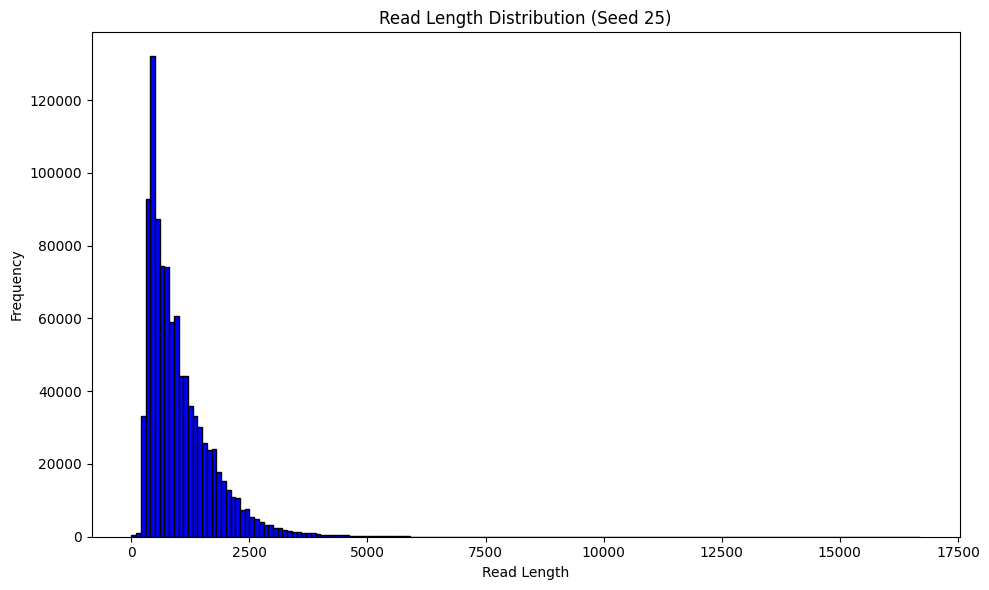

In [6]:
import matplotlib.pyplot as plt
import pysam
import os
import random
import csv
import numpy as np
from concurrent.futures import ThreadPoolExecutor

# Function to index BAM files if not already indexed
def index_bam_files(bam_files):
    for bam_file in bam_files:
        if not os.path.exists(bam_file + ".bai"):
            pysam.index(bam_file)

# Function to subsample BAM files using pysam and random
def subsample_bam_file(bam_file, output_file, num_reads, seed):
    random.seed(seed)
    with pysam.AlignmentFile(bam_file, "rb", check_sq=False) as bam_in:
        total_reads = bam_in.mapped + bam_in.unmapped
        selected_indices = set(random.sample(range(total_reads), num_reads))
        with pysam.AlignmentFile(output_file, "wb", header=bam_in.header) as bam_out:
            for i, read in enumerate(bam_in.fetch(until_eof=True)):
                if i in selected_indices:
                    bam_out.write(read)

# Generator function to extract read lengths from BAM files
def read_lengths_generator(bam_file):
    with pysam.AlignmentFile(bam_file, "rb", check_sq=False) as bam:
        for read in bam.fetch(until_eof=True):
            yield read.query_length

def process_bam_file(bam_file, num_reads, seed):
    subsampled_bam_file = f"subsampled1M_{os.path.basename(bam_file)}"
    subsample_bam_file(bam_file, subsampled_bam_file, num_reads, seed)
    
    read_lengths = list(read_lengths_generator(subsampled_bam_file))
    
    os.remove(subsampled_bam_file)  # Clean up the subsampled BAM file
    
    return read_lengths

def write_tsv_file(seed, read_lengths, bin_size=100):
    max_length = max(read_lengths)
    bins = range(0, max_length + bin_size, bin_size)
    frequencies, _ = np.histogram(read_lengths, bins=bins)
    
    tsv_file = f'read_length_frequencies_seed_{seed}.tsv'
    with open(tsv_file, 'w', newline='') as file:
        writer = csv.writer(file, delimiter='\t')
        writer.writerow(['Bin', 'Frequency'])
        for bin_start, frequency in zip(bins[:-1], frequencies):
            writer.writerow([bin_start, frequency])

def plot_read_length_distribution(bam_files, num_reads=1000000, seeds=[24, 25], max_workers=16):
    # Index BAM files
    index_bam_files(bam_files)

    num_reads_per_file = num_reads // len(bam_files)

    for seed in seeds:
        all_read_lengths = []

        with ThreadPoolExecutor(max_workers=max_workers) as executor:
            futures = [executor.submit(process_bam_file, bam_file, num_reads_per_file, seed) for bam_file in bam_files]
            for future in futures:
                all_read_lengths.extend(future.result())

        # Write TSV file
        write_tsv_file(seed, all_read_lengths)

        # Determine the maximum read length for binning
        max_length = max(all_read_lengths)

        # Plot configurations
        plot_configs = [
            {"log_scale": True, "xlim": (0, 4000), "suffix": "log_xlim"},
            {"log_scale": True, "xlim": None, "suffix": "log_no_xlim"},
            {"log_scale": False, "xlim": (0, 4000), "suffix": "no_log_xlim"},
            {"log_scale": False, "xlim": None, "suffix": "no_log_no_xlim"}
        ]

        for config in plot_configs:
            plt.figure(figsize=(10, 6))
            plt.hist(all_read_lengths, bins=range(0, max_length + 100, 100), color='blue', edgecolor='black')
            plt.title(f'Read Length Distribution (Seed {seed})')
            plt.xlabel('Read Length')
            plt.ylabel('Frequency')
            if config["log_scale"]:
                plt.yscale('log')
            if config["xlim"]:
                plt.xlim(config["xlim"])
            plt.tight_layout()
            plt.savefig(f'read_length_distribution_seed_{seed}_{config["suffix"]}.png')
            plt.show()

if __name__ == "__main__":
    bam_files = ["morf.set2.skera1.bam", "morf.set2.skera2.bam"]
    plot_read_length_distribution(bam_files)

In [15]:
import matplotlib.pyplot as plt
import pysam
import os
import random
import csv
import numpy as np
from concurrent.futures import ThreadPoolExecutor

def index_bam_files(bam_files):
    for bam_file in bam_files:
        if not os.path.exists(bam_file + ".bai"):
            pysam.index(bam_file)

def subsample_bam_file(bam_file, output_file, num_reads, seed, mapped=True):
    random.seed(seed)
    with pysam.AlignmentFile(bam_file, "rb", check_sq=False) as bam_in:
        if mapped:
            primary_reads = [read for read in bam_in if not read.is_secondary and not read.is_supplementary and not read.is_unmapped]
            total_reads = len(primary_reads)
            fetch_func = lambda: primary_reads
        else:
            total_reads = bam_in.unmapped
            fetch_func = lambda: bam_in.fetch(until_eof=True)
        
        if total_reads == 0:
            print(f"No reads found in {bam_file}.")
            return
        
        selected_indices = set(random.sample(range(total_reads), num_reads))
        with pysam.AlignmentFile(output_file, "wb", header=bam_in.header) as bam_out:
            for i, read in enumerate(fetch_func()):
                if i in selected_indices:
                    bam_out.write(read)

def read_lengths_generator(bam_file):
    with pysam.AlignmentFile(bam_file, "rb", check_sq=False) as bam:
        for read in bam.fetch(until_eof=True):
            yield read.query_length

def process_bam_file(bam_file, num_reads, seed, mapped=True):
    subsampled_bam_file = f"subsampled1M_{os.path.basename(bam_file)}"
    subsample_bam_file(bam_file, subsampled_bam_file, num_reads, seed, mapped)
    
    read_lengths = list(read_lengths_generator(subsampled_bam_file))
    
    os.remove(subsampled_bam_file)
    
    if not read_lengths:
        print(f"No read lengths found in {subsampled_bam_file}.")
    
    return read_lengths

def write_tsv_file(seed, read_lengths, output_prefix, bin_size=100):
    if not read_lengths:
        print(f"No read lengths found for seed {seed}. Skipping TSV file creation.")
        return
    
    max_length = max(read_lengths)
    bins = range(0, max_length + bin_size, bin_size)
    frequencies, _ = np.histogram(read_lengths, bins=bins)
    
    tsv_file = f'{output_prefix}_read_length_frequencies_seed_{seed}.tsv'
    with open(tsv_file, 'w', newline='') as file:
        writer = csv.writer(file, delimiter='\t')
        writer.writerow(['Bin', 'Frequency'])
        for bin_start, frequency in zip(bins[:-1], frequencies):
            writer.writerow([bin_start, frequency])

def plot_read_length_distribution(bam_files, output_prefix, num_reads=1000000, seeds=[24, 25], max_workers=16, mapped=True):
    index_bam_files(bam_files)

    num_reads_per_file = num_reads // len(bam_files)

    for seed in seeds:
        all_read_lengths = []

        with ThreadPoolExecutor(max_workers=max_workers) as executor:
            futures = [executor.submit(process_bam_file, bam_file, num_reads_per_file, seed, mapped) for bam_file in bam_files]
            for future in futures:
                all_read_lengths.extend(future.result())

        if not all_read_lengths:
            print(f"No read lengths found for seed {seed}. Skipping plotting.")
            continue

        write_tsv_file(seed, all_read_lengths, output_prefix)

        max_length = max(all_read_lengths)

        plot_configs = [
            {"log_scale": True, "xlim": (0, 4000), "suffix": "log_xlim"},
            {"log_scale": True, "xlim": None, "suffix": "log_no_xlim"},
            {"log_scale": False, "xlim": (0, 4000), "suffix": "no_log_xlim"},
            {"log_scale": False, "xlim": None, "suffix": "no_log_no_xlim"}
        ]

        for config in plot_configs:
            plt.figure(figsize=(10, 6))
            plt.hist(all_read_lengths, bins=range(0, max_length + 100, 100), color='blue', edgecolor='black')
            plt.title(f'Read Length Distribution (Seed {seed})')
            plt.xlabel('Read Length')
            plt.ylabel('Frequency')
            if config["log_scale"]:
                plt.yscale('log')
            if config["xlim"]:
                plt.xlim(config["xlim"])
            plt.tight_layout()
            plt.savefig(f'{output_prefix}_read_length_distribution_seed_{seed}_{config["suffix"]}.png')
            plt.close()

def process_bam_files_set(bam_files_set, output_prefix, num_reads=1000000, seeds=[24], max_workers=16, mapped=True):
    for set_name, bam_files in bam_files_set.items():
        plot_read_length_distribution(bam_files, f'{output_prefix}_{set_name}', num_reads, seeds, max_workers, mapped)

if __name__ == "__main__":
    bam_files_set0 = {
        "N0_R1": [
            "morf.set2.lima1.bc01_5p--3p.bam",
            "morf.set2.lima2.bc01_5p--3p.bam"
        ],
        "N0_R2": [
            "morf.set2.lima1.bc02_5p--3p.bam",
            "morf.set2.lima2.bc02_5p--3p.bam"
        ],
        "N0_R3": [
            "morf.set2.lima1.bc03_5p--3p.bam",
            "morf.set2.lima2.bc03_5p--3p.bam"
        ],
        "N14_R1": [
            "morf.set2.lima1.bc04_5p--3p.bam",
            "morf.set2.lima2.bc04_5p--3p.bam"
        ],
        "N14_R2": [
            "morf.set2.lima1.bc05_5p--3p.bam",
            "morf.set2.lima2.bc05_5p--3p.bam"
        ],
        "N14_R3": [
            "morf.set2.lima1.bc06_5p--3p.bam",
            "morf.set2.lima2.bc06_5p--3p.bam"
        ]
    }

    bam_sets = {
        "set1": [
            "morf.N0_R1.merged.sorted.bam",
            "morf.N0_R2.merged.sorted.bam",
            "morf.N0_R3.merged.sorted.bam",
            "morf.N14_R1.merged.sorted.bam",
            "morf.N14_R2.merged.sorted.bam",
            "morf.N14_R3.merged.sorted.bam"
        ],
        "set2": [
            "morf.N0_R1.merged.sorted_forward.bam",
            "morf.N0_R2.merged.sorted_forward.bam",
            "morf.N0_R3.merged.sorted_forward.bam",
            "morf.N14_R1.merged.sorted_forward.bam",
            "morf.N14_R2.merged.sorted_forward.bam",
            "morf.N14_R3.merged.sorted_forward.bam"
        ],
        "set3": [
            "morf.N0_R1.last_base_filtered.withTN_UI.soft_clipped.sorted.bam",
            "morf.N0_R2.last_base_filtered.withTN_UI.soft_clipped.sorted.bam",
            "morf.N0_R3.last_base_filtered.withTN_UI.soft_clipped.sorted.bam",
            "morf.N14_R1.last_base_filtered.withTN_UI.soft_clipped.sorted.bam",
            "morf.N14_R2.last_base_filtered.withTN_UI.soft_clipped.sorted.bam",
            "morf.N14_R3.last_base_filtered.withTN_UI.soft_clipped.sorted.bam"
        ],
        "set4": [
            "morf.N14_R1.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.bam",
            "morf.N14_R2.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.bam",
            "morf.N14_R3.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.bam"
        ]
    }

    for set_name, bam_files in bam_sets.items():
        for bam_file in bam_files:
            plot_read_length_distribution([bam_file], f'{set_name}_{os.path.basename(bam_file).split(".")[1]}', seeds=[24])
            
    process_bam_files_set(bam_files_set0, "set0", mapped=False)

##### PacBio_vs_ONT_read_length_distribution

In [25]:
import os
import pandas as pd
import matplotlib.pyplot as plt

def read_tsv_file(file_path):
    return pd.read_csv(file_path, sep='\t')

def inspect_tsv_file(file_path):
    df = pd.read_csv(file_path, sep='\t')
    print(f"Columns in {file_path}: {df.columns.tolist()}")
    return df

def plot_read_length_distribution(ont_file, pacbio_file, output_prefix):
    ont_data = read_tsv_file(ont_file)
    pacbio_data = read_tsv_file(pacbio_file)

    # Print total sum of the Frequency column for both files
    ont_total_frequency = ont_data['Frequency'].sum()
    pacbio_total_frequency = pacbio_data['Frequency'].sum()
    print(f"Total Frequency for ONT ({ont_file}): {ont_total_frequency}")
    print(f"Total Frequency for PacBio ({pacbio_file}): {pacbio_total_frequency}")

    plot_configs = [
        {"log_scale": True, "xlim": (0, 8000), "suffix": "log_xlim"},
        {"log_scale": True, "xlim": None, "suffix": "log_no_xlim"},
        {"log_scale": False, "xlim": (0, 8000), "suffix": "no_log_xlim"},
        {"log_scale": False, "xlim": None, "suffix": "no_log_no_xlim"}
    ]

    for config in plot_configs:
        plt.figure(figsize=(10, 6))
        plt.plot(ont_data['Bin_Start'], ont_data['Frequency'], 'o-', label='ONT')
        plt.plot(pacbio_data['Bin'], pacbio_data['Frequency'], 'o-', label='PacBio')
        plt.title(f'Read Length Distribution Comparison ({config["suffix"]})')
        plt.xlabel('Read Length')
        plt.ylabel('Frequency')
        if config["log_scale"]:
            plt.yscale('log')
        if config["xlim"]:
            plt.xlim(config["xlim"])
        plt.legend()
        plt.tight_layout()
        plt.savefig(f'{output_prefix}_{config["suffix"]}.png')
        plt.close()

def main():
    ont_folder = 'Read_length_frequency_ont'
    pacbio_folder = 'Read_length_frequency_pacbio'
    output_folder = 'PacBio_vs_ONT_read_length_distribution'

    if not os.path.exists(output_folder):
        os.makedirs(output_folder)

    # Mapping of bc to N0_R
    mapping = {
        'bc01': 'N0_R1',
        'bc02': 'N0_R2',
        'bc03': 'N0_R3',
        'bc04': 'N14_R1',
        'bc05': 'N14_R2',
        'bc06': 'N14_R3'
    }

    sets = ['set0', 'set1', 'set2', 'set3', 'set4']

    for set_name in sets:
        for bc, nr in mapping.items():
            # Skip invalid combinations for set4
            if set_name == 'set4' and bc not in ['bc04', 'bc05', 'bc06']:
                continue

            ont_file = os.path.join(ont_folder, f'{set_name}_{bc}_read_length_distribution_seed_24.tsv')
            pacbio_file = os.path.join(pacbio_folder, f'{set_name}_{nr}_read_length_frequencies_seed_24.tsv')
            
            # Check if files exist before processing
            if not os.path.exists(ont_file) or not os.path.exists(pacbio_file):
                print(f"Skipping {ont_file} or {pacbio_file} as one of them does not exist.")
                continue

            # Inspect column names
            inspect_tsv_file(ont_file)
            inspect_tsv_file(pacbio_file)
            
            output_prefix = os.path.join(output_folder, f'{set_name}_{bc}_vs_{nr}')
            plot_read_length_distribution(ont_file, pacbio_file, output_prefix)

    # Additional plots for read_length_distribution_seed_24.tsv and read_length_distribution_seed_25.tsv
    for seed in [24, 25]:
        ont_file = os.path.join(ont_folder, f'read_length_distribution_seed_{seed}.tsv')
        pacbio_file = os.path.join(pacbio_folder, f'read_length_distribution_seed_{seed}.tsv')
        
        # Check if files exist before processing
        if not os.path.exists(ont_file) or not os.path.exists(pacbio_file):
            print(f"Skipping {ont_file} or {pacbio_file} as one of them does not exist.")
            continue

        # Inspect column names
        inspect_tsv_file(ont_file)
        inspect_tsv_file(pacbio_file)
        
        output_prefix = os.path.join(output_folder, f'read_length_distribution_seed_{seed}')
        plot_read_length_distribution(ont_file, pacbio_file, output_prefix)

if __name__ == "__main__":
    main()

Columns in Read_length_frequency_ont/set0_bc01_read_length_distribution_seed_24.tsv: ['Bin_Start', 'Bin_End', 'Frequency']
Columns in Read_length_frequency_pacbio/set0_N0_R1_read_length_frequencies_seed_24.tsv: ['Bin', 'Frequency']
Total Frequency for ONT (Read_length_frequency_ont/set0_bc01_read_length_distribution_seed_24.tsv): 1000000.0
Total Frequency for PacBio (Read_length_frequency_pacbio/set0_N0_R1_read_length_frequencies_seed_24.tsv): 1000000
Columns in Read_length_frequency_ont/set0_bc02_read_length_distribution_seed_24.tsv: ['Bin_Start', 'Bin_End', 'Frequency']
Columns in Read_length_frequency_pacbio/set0_N0_R2_read_length_frequencies_seed_24.tsv: ['Bin', 'Frequency']
Total Frequency for ONT (Read_length_frequency_ont/set0_bc02_read_length_distribution_seed_24.tsv): 1000000.0
Total Frequency for PacBio (Read_length_frequency_pacbio/set0_N0_R2_read_length_frequencies_seed_24.tsv): 1000000
Columns in Read_length_frequency_ont/set0_bc03_read_length_distribution_seed_24.tsv: ['B

In [2]:
import pysam

# Initialize a dictionary to store read counts
counts = {}

# Loop through bc01 to bc12 and count reads
for i in range(1, 13):
    bc = f"bc{i:02d}"
    bam_file = f"morf.set2.lima2.{bc}_5p--3p.bam"
    try:
        with pysam.AlignmentFile(bam_file, "rb", check_sq=False) as bam:
            count = bam.count(until_eof=True)
            counts[bc] = count
            print(f"{bc}: {count} reads")
    except ValueError as e:
        print(f"Error processing {bam_file}: {e}")

# Sum counts for bc01 to bc06
sum_01_06 = sum(counts[f"bc{i:02d}"] for i in range(1, 7))
print(f"Sum of reads from bc01 to bc06: {sum_01_06}")

# Sum counts for bc07 to bc12
sum_07_12 = sum(counts[f"bc{i:02d}"] for i in range(7, 13))
print(f"Sum of reads from bc07 to bc12: {sum_07_12}")

# Calculate the ratio
ratio = sum_01_06 / sum_07_12 if sum_07_12 != 0 else float('inf')
print(f"Ratio of sum_01_06 to sum_07_12: {ratio:.2f}")

bc01: 5411713 reads
bc02: 5209463 reads
bc03: 5160734 reads
bc04: 6967007 reads
bc05: 6943706 reads
bc06: 6758064 reads
bc07: 118 reads
bc08: 22 reads
bc09: 8 reads
bc10: 76 reads
bc11: 12 reads
bc12: 6 reads
Sum of reads from bc01 to bc06: 36450687
Sum of reads from bc07 to bc12: 242
Ratio of sum_01_06 to sum_07_12: 150622.67


##### work from here to generate dedup bams

In [1]:
import pysam
import pandas as pd
import subprocess
import os

# Define the input BAM files
bam_files = [
    "morf.N14_R1.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.bam",
    "morf.N14_R2.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.bam",
    "morf.N14_R3.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.bam"
]

# Read the transfer table into a DataFrame
transfer_table = pd.read_csv("transfer_table.tsv", sep="\t")

# Strip whitespace from column names
transfer_table.columns = transfer_table.columns.str.strip()

# Convert the transfer table into a dictionary
transcript_dict = dict(zip(transfer_table["transcript_name"], transfer_table["transcript_id"]))

# Function to convert BAM to FASTA using samtools
def bam_to_fasta_samtools(bam_file, fasta_file):
    command = f"/opt/conda/envs/mas_seq/bin/samtools fasta -T TN,UI {bam_file} > {fasta_file}"
    subprocess.run(command, shell=True, check=True)
    print(f"Converted {bam_file} to {fasta_file}")

# Function to filter and update TN tag in FASTA file
def filter_and_update_fasta(fasta_file, updated_fasta_file, transcript_dict):
    total_reads = 0
    matched_reads = 0
    with open(fasta_file, "r") as infile, open(updated_fasta_file, "w") as outfile:
        for line in infile:
            if line.startswith(">"):
                total_reads += 1
                header = line.strip()
                seq_name = header.split()[0][1:]
                tn_tag = header.split("TN:")[1].split()[0] if "TN:" in header else ""
                tn_tag = tn_tag.replace("Z:", "")  # Remove the Z: prefix
                if tn_tag in transcript_dict:
                    matched_reads += 1
                    new_tn_tag = transcript_dict[tn_tag]
                    ui_tag = header.split("UI:")[1] if "UI:" in header else ""
                    new_header = f">{seq_name}\tTN:Z:{new_tn_tag}\tUI:{ui_tag}"
                    outfile.write(f"{new_header}\n")
                    seq = next(infile).strip()
                    outfile.write(f"{seq}\n")
    
    print(f"Processed {fasta_file}")
    print(f"Total reads: {total_reads}")
    print(f"Matched reads: {matched_reads}")

# Function to map FASTA to reference genome using minimap2 and convert to sorted BAM
def map_fasta_to_bam_first(fasta_file, bam_file, reference_fa):
    sorted_bam_file = bam_file.replace(".bam", "_sorted.bam")
    command = (
        f"/opt/conda/envs/mas_seq/bin/minimap2 -y --secondary=no -a -t 96 {reference_fa} {fasta_file} | "
        f"/opt/conda/envs/mas_seq/bin/samtools view -b | "
        f"/opt/conda/envs/mas_seq/bin/samtools sort -o {sorted_bam_file}"
    )
    try:
        subprocess.run(command, shell=True, check=True)
    except subprocess.CalledProcessError as e:
        print(f"Error running minimap2 and samtools pipeline: {e}")
        return None
    
    return sorted_bam_file

# Function to map trimmed FASTA to reference genome using minimap2 and convert to sorted BAM
def map_fasta_to_bam_second(fasta_file, bam_file, reference_fa, junc_bed):
    sorted_bam_file = bam_file.replace(".bam", "_final_sorted.bam")
    command = (
        f"/opt/conda/envs/mas_seq/bin/minimap2 -y -a -uf -x splice:hq --secondary=yes -Y -t 96 --cs=long "
        f"--junc-bed {junc_bed} {reference_fa} {fasta_file} | "
        f"/opt/conda/envs/mas_seq/bin/samtools view -b | "
        f"/opt/conda/envs/mas_seq/bin/samtools sort -o {sorted_bam_file}"
    )
    try:
        subprocess.run(command, shell=True, check=True)
    except subprocess.CalledProcessError as e:
        print(f"Error running minimap2 and samtools pipeline: {e}")
        return None
    
    return sorted_bam_file

# Function to remove soft clipping from a read and return the trimmed sequence
def trim_soft_clipping(read):
    if read.cigartuples is None:
        return read.query_sequence

    new_seq = read.query_sequence
    start = 0
    end = len(new_seq)

    # Trim 5' soft clipping
    if read.cigartuples[0][0] == 4:  # Soft clipping (S) at the beginning
        start = read.cigartuples[0][1]

    # Trim 3' soft clipping
    if read.cigartuples[-1][0] == 4:  # Soft clipping (S) at the end
        end -= read.cigartuples[-1][1]

    return new_seq[start:end]

# Function to convert BAM to FASTA, trimming soft clipping based on CIGAR
def bam_to_fasta_trimmed(bam_file, fasta_file):
    total_reads = 0
    trimmed_reads = 0
    with pysam.AlignmentFile(bam_file, "rb") as infile, open(fasta_file, "w") as outfile:
        for read in infile:
            if read.is_secondary or read.is_supplementary or read.is_unmapped or read.is_reverse:
                continue  # Skip secondary, supplementary, unmapped, and reverse strand reads
            
            total_reads += 1
            trimmed_seq = trim_soft_clipping(read)
            if trimmed_seq:
                trimmed_reads += 1
                tn_tag = read.get_tag("TN") if read.has_tag("TN") else ""
                ui_tag = read.get_tag("UI") if read.has_tag("UI") else ""
                header = f">{read.query_name}\tTN:Z:{tn_tag}"
                if ui_tag:
                    header += f"\tUI:Z:{ui_tag}"
                outfile.write(f"{header}\n")
                outfile.write(f"{trimmed_seq}\n")
    
    print(f"Processed {bam_file}")
    print(f"Total reads: {total_reads}")
    print(f"Trimmed reads: {trimmed_reads}")

# Function to index the final BAM file
def index_bam(bam_file):
    command = f"/opt/conda/envs/mas_seq/bin/samtools index {bam_file}"
    subprocess.run(command, shell=True, check=True)

def main():
    reference_fa_first = "/home/jupyter/projects/morf/morf.fasta"
    reference_fa_second = "minigenome.fa"
    junc_bed = "minigenome.UTRs_trimmed.bed"

    for bam_file in bam_files:
        # Step 1: Convert the original BAM file to FASTA using samtools
        fasta_file = bam_file.replace(".bam", ".fasta")
        bam_to_fasta_samtools(bam_file, fasta_file)
        
        # Step 2: Filter and update TN tag in the FASTA file
        updated_fasta_file = fasta_file.replace(".fasta", "_updated.fasta")
        filter_and_update_fasta(fasta_file, updated_fasta_file, transcript_dict)
        
        # Step 3: Map the updated FASTA reads to the genome and convert to sorted BAM (first run)
        bam_file_output = bam_file.replace(".bam", "_mapped.bam")
        sorted_bam_file = map_fasta_to_bam_first(updated_fasta_file, bam_file_output, reference_fa_first)
        
        # Step 4: Convert the sorted BAM file to FASTA, trimming soft clipping
        trimmed_fasta_file = sorted_bam_file.replace(".bam", ".trimmed.fasta")
        bam_to_fasta_trimmed(sorted_bam_file, trimmed_fasta_file)
        
        # Step 5: Map the trimmed FASTA file to the genome and convert to sorted BAM (second run)
        final_bam_file = trimmed_fasta_file.replace(".fasta", ".bam")
        final_sorted_bam_file = map_fasta_to_bam_second(trimmed_fasta_file, final_bam_file, reference_fa_second, junc_bed)
        
        # Step 6: Index the final sorted BAM file
        index_bam(final_sorted_bam_file)

if __name__ == "__main__":
    main()

[M::bam2fq_mainloop] discarded 0 singletons
[M::bam2fq_mainloop] processed 1654959 reads


Converted morf.N14_R1.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.bam to morf.N14_R1.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.fasta
Processed morf.N14_R1.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.fasta
Total reads: 1654959
Matched reads: 1508109


[M::mm_idx_gen::0.639*0.38] collected minimizers
[M::mm_idx_gen::0.666*1.02] sorted minimizers
[M::main::0.667*1.02] loaded/built the index for 3550 target sequence(s)
[M::mm_mapopt_update::0.689*1.02] mid_occ = 53
[M::mm_idx_stat] kmer size: 15; skip: 10; is_hpc: 0; #seq: 3550
[M::mm_idx_stat::0.702*1.02] distinct minimizers: 573568 (52.66% are singletons); average occurrences: 1.969; average spacing: 5.407; total length: 6105645
[M::worker_pipeline::33.382*60.80] mapped 579562 sequences
[M::worker_pipeline::46.761*56.46] mapped 547934 sequences
[M::worker_pipeline::50.864*51.92] mapped 380613 sequences
[M::main] Version: 2.28-r1209
[M::main] CMD: /opt/conda/envs/mas_seq/bin/minimap2 -y --secondary=no -a -t 96 /home/jupyter/projects/morf/morf.fasta morf.N14_R1.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup_updated.fasta
[M::main] Real time: 50.962 sec; CPU: 2641.159 sec; Peak RSS: 2.182 GB
[bam_sort_core] merging from 2 files and 1 in-memory blocks...


Processed morf.N14_R1.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup_mapped_sorted.bam
Total reads: 1485381
Trimmed reads: 1485381


[M::mm_idx_gen::1.546*1.00] collected minimizers
[M::mm_idx_gen::1.882*3.22] sorted minimizers
[M::main::1.882*3.22] loaded/built the index for 1566 target sequence(s)
[M::mm_mapopt_update::2.078*3.01] mid_occ = 89
[M::mm_idx_stat] kmer size: 15; skip: 5; is_hpc: 0; #seq: 1566
[M::mm_idx_stat::2.223*2.88] distinct minimizers: 7849055 (91.84% are singletons); average occurrences: 1.228; average spacing: 2.932; total length: 28250975
[M::worker_pipeline::69.317*74.49] mapped 637438 sequences
[M::worker_pipeline::94.408*64.69] mapped 614624 sequences
[M::worker_pipeline::102.214*59.79] mapped 233319 sequences
[M::main] Version: 2.28-r1209
[M::main] CMD: /opt/conda/envs/mas_seq/bin/minimap2 -y -a -uf -x splice:hq --secondary=yes -Y -t 96 --cs=long --junc-bed minigenome.UTRs_trimmed.bed minigenome.fa morf.N14_R1.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup_mapped_sorted.trimmed.fasta
[M::main] Real time: 102.420 sec; CPU: 6111.642 sec; Peak RSS: 6.855 GB
[bam_sort_core] merging fr

Converted morf.N14_R2.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.bam to morf.N14_R2.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.fasta
Processed morf.N14_R2.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.fasta
Total reads: 1615413
Matched reads: 1471593


... (3 outputs left out)

Converted morf.N14_R3.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.bam to morf.N14_R3.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.fasta
Processed morf.N14_R3.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup.fasta
Total reads: 1580586
Matched reads: 1440322


[M::mm_idx_gen::0.230*1.01] collected minimizers
[M::mm_idx_gen::0.268*2.32] sorted minimizers
[M::main::0.268*2.32] loaded/built the index for 3550 target sequence(s)
[M::mm_mapopt_update::0.291*2.22] mid_occ = 53
[M::mm_idx_stat] kmer size: 15; skip: 10; is_hpc: 0; #seq: 3550
[M::mm_idx_stat::0.304*2.17] distinct minimizers: 573568 (52.66% are singletons); average occurrences: 1.969; average spacing: 5.407; total length: 6105645
[M::worker_pipeline::28.661*69.15] mapped 574094 sequences
[M::worker_pipeline::40.392*61.32] mapped 560563 sequences
[M::worker_pipeline::43.859*56.50] mapped 305665 sequences
[M::main] Version: 2.28-r1209
[M::main] CMD: /opt/conda/envs/mas_seq/bin/minimap2 -y --secondary=no -a -t 96 /home/jupyter/projects/morf/morf.fasta morf.N14_R3.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup_updated.fasta
[M::main] Real time: 43.925 sec; CPU: 2478.159 sec; Peak RSS: 2.171 GB
[bam_sort_core] merging from 2 files and 1 in-memory blocks...


Processed morf.N14_R3.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup_mapped_sorted.bam
Total reads: 1418658
Trimmed reads: 1418658


[M::mm_idx_gen::1.681*1.00] collected minimizers
[M::mm_idx_gen::2.857*4.12] sorted minimizers
[M::main::2.857*4.12] loaded/built the index for 1566 target sequence(s)
[M::mm_mapopt_update::3.076*3.89] mid_occ = 89
[M::mm_idx_stat] kmer size: 15; skip: 5; is_hpc: 0; #seq: 1566
[M::mm_idx_stat::3.231*3.76] distinct minimizers: 7849055 (91.84% are singletons); average occurrences: 1.228; average spacing: 2.932; total length: 28250975
[M::worker_pipeline::75.469*75.71] mapped 638590 sequences
[M::worker_pipeline::98.976*63.80] mapped 614422 sequences
[M::worker_pipeline::105.178*60.07] mapped 165646 sequences
[M::main] Version: 2.28-r1209
[M::main] CMD: /opt/conda/envs/mas_seq/bin/minimap2 -y -a -uf -x splice:hq --secondary=yes -Y -t 96 --cs=long --junc-bed minigenome.UTRs_trimmed.bed minigenome.fa morf.N14_R3.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup_mapped_sorted.trimmed.fasta
[M::main] Real time: 105.364 sec; CPU: 6317.860 sec; Peak RSS: 6.409 GB
[bam_sort_core] merging fr

In [1]:
# Run the external Python script
%run morf_annotation_filtering_pacbio.py

Error.  nthreads cannot be larger than environment variable "NUMEXPR_MAX_THREADS" (64)/home/jupyter/projects/morf2/LRAA_pylib/Transcript.py:386: SyntaxWarning: invalid escape sequence '\S'
  m = re.match('^(\S+) \\"([^\\"]+)\\"', part)
/home/jupyter/projects/morf2/LRAA_pylib/Util_funcs.py:25: SyntaxWarning: invalid escape sequence '\s'
  contig_seq_str = re.sub("\s", "", contig_seq_str) # just in case


// Processing minig-ZNF322
Got 30 alignments on contig minig-ZNF322
transcript_id: ENST00000471278.5
// Processing minig-MLLT10
Got 50 alignments on contig minig-MLLT10
transcript_id: ENST00000377072.8
transcript_id: ENST00000377059.7
// Processing minig-YWHAE
Got 979 alignments on contig minig-YWHAE
transcript_id: ENST00000264335.13
// Processing minig-ZNF362
Got 499 alignments on contig minig-ZNF362
transcript_id: ENST00000373428.5
// Processing minig-ZSCAN10
Got 1318 alignments on contig minig-ZSCAN10
transcript_id: ENST00000538082.5
transcript_id: ENST00000575108.5
// Processing minig-NFKBIZ
Got 228 alignments on contig minig-NFKBIZ
transcript_id: ENST00000326172.9
transcript_id: ENST00000394054.6
// Processing minig-ZNF597
Got 115 alignments on contig minig-ZNF597
transcript_id: ENST00000301744.7
// Processing minig-SMARCB1
Got 1655 alignments on contig minig-SMARCB1
transcript_id: ENST00000644036.2
transcript_id: ENST00000344921.11
transcript_id: ENST00000407422.8
// Processing m

In [4]:
import subprocess

# Define the input BAM files
bam_files = [
    "morf.N14_R1.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup_mapped_sorted.trimmed_final_sorted_annot_compat.bam",
    "morf.N14_R2.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup_mapped_sorted.trimmed_final_sorted_annot_compat.bam",
    "morf.N14_R3.last_base_filtered.withTN_UI.soft_clipped.sorted_dedup_mapped_sorted.trimmed_final_sorted_annot_compat.bam"
]

# Define the output BAM file names
merged_bam = "morf2_pacbio_merged_annot_compat_sorted.bam"
merged_bam_index = "morf2_pacbio_merged_annot_compat_sorted.bam.bai"

# Step 1: Merge the BAM files
merge_command = ["/opt/conda/envs/mas_seq/bin/samtools", "merge", merged_bam] + bam_files
subprocess.run(merge_command, check=True)
print(f"Merged BAM file created: {merged_bam}")

# Step 2: Sort the merged BAM file
sorted_bam = merged_bam
sort_command = ["/opt/conda/envs/mas_seq/bin/samtools", "sort", "-o", sorted_bam, merged_bam]
subprocess.run(sort_command, check=True)
print(f"Sorted BAM file created: {sorted_bam}")

# Step 3: Index the sorted BAM file
index_command = ["/opt/conda/envs/mas_seq/bin/samtools", "index", sorted_bam]
subprocess.run(index_command, check=True)
print(f"Index file created: {merged_bam_index}")

# Step 4: Count the primary alignments
count_command = ["/opt/conda/envs/mas_seq/bin/samtools", "view", "-c", "-F", "2304", sorted_bam]  # -F 2304 to exclude secondary, supplementary, and unmapped reads
result = subprocess.run(count_command, capture_output=True, text=True, check=True)
primary_alignments = int(result.stdout.strip())
print(f"Total number of primary alignments: {primary_alignments}")

Merged BAM file created: morf2_pacbio_merged_annot_compat_sorted.bam


[bam_sort_core] merging from 12 files and 1 in-memory blocks...


Sorted BAM file created: morf2_pacbio_merged_annot_compat_sorted.bam
Index file created: morf2_pacbio_merged_annot_compat_sorted.bam.bai
Total number of primary alignments: 4201523


In [5]:
#!/usr/bin/env python
import pysam
from collections import defaultdict

def count_tn_occurrences(bam_file, output_tsv):
    tn_counts = defaultdict(int)
    total_reads = 0
    
    with pysam.AlignmentFile(bam_file, "rb") as infile:
        for read in infile:
            if read.is_secondary or read.is_unmapped or read.is_supplementary:
                continue  # Skip secondary, unmapped, and supplementary alignments
            
            total_reads += 1
            
            if read.has_tag("TN"):
                tn_tag = read.get_tag("TN")
                tn_counts[tn_tag] += 1
    
    with open(output_tsv, "w") as outfile:
        for tn_tag, count in tn_counts.items():
            outfile.write(f"{tn_tag}\t{count}\n")
    
    print(f"Total number of reads processed: {total_reads}")

def main():
    bam_file = "morf2_pacbio_merged_annot_compat_sorted.bam"
    output_tsv = "morf2_pacbio_merged_annot_compat_sorted_tn_counts.tsv"
    count_tn_occurrences(bam_file, output_tsv)

if __name__ == '__main__':
    main()

Total number of reads processed: 4201523


In [6]:
### To ensure that the records are ordered correctly (gene, transcript, exon) and to remove all CDS records, we updated the write_gtf function. Here is the updated script:
#!/usr/bin/env python

import random
import pandas as pd
import gffutils
from collections import defaultdict

def parse_gtf(gtf_file):
    db = gffutils.create_db(gtf_file, dbfn=':memory:', force=True, keep_order=True, merge_strategy='merge', sort_attribute_values=True, disable_infer_transcripts=True, disable_infer_genes=True)
    genes = defaultdict(lambda: defaultdict(list))
    for feature in db.all_features():
        if feature.featuretype == 'transcript':
            gene_id = feature.attributes.get('gene_id', [None])[0]
            transcript_id = feature.attributes.get('transcript_id', [None])[0]
            genes[gene_id][transcript_id].append(feature)
        elif feature.featuretype in ['exon']:
            gene_id = feature.attributes.get('gene_id', [None])[0]
            transcript_id = feature.attributes.get('transcript_id', [None])[0]
            genes[gene_id][transcript_id].append(feature)
    return genes

def write_gtf(genes, output_file, original_gtf):
    gene_records = {}
    with open(original_gtf) as infile:
        for line in infile:
            if "\tgene\t" in line:
                gene_id = line.split('gene_id "')[1].split('"')[0]
                gene_records[gene_id] = line

    with open(output_file, "w") as outfile:
        for gene_id, transcripts in genes.items():
            if gene_id in gene_records:
                outfile.write(gene_records[gene_id])
            for transcript_id, features in transcripts.items():
                transcripts = [f for f in features if f.featuretype == 'transcript']
                exons = [f for f in features if f.featuretype == 'exon']
                for transcript in transcripts:
                    outfile.write(str(transcript) + "\n")
                for exon in exons:
                    outfile.write(str(exon) + "\n")

def generate_reduced_gtf(genes, output_file, original_gtf, percentage=80):
    random.seed(42)
    reduced_genes = defaultdict(lambda: defaultdict(list))
    for gene_id, transcripts in genes.items():
        transcript_ids = list(transcripts.keys())
        if percentage == 100:
            # Select only one transcript per gene
            selected_transcripts = [random.choice(transcript_ids)]
        else:
            if len(transcript_ids) > 1:
                num_to_keep = max(1, int(len(transcript_ids) * (percentage / 100.0)))
                selected_transcripts = random.sample(transcript_ids, num_to_keep)
            else:
                # Randomly decide whether to keep the single transcript
                selected_transcripts = transcript_ids if random.random() < (percentage / 100.0) else []
        for transcript_id in selected_transcripts:
            reduced_genes[gene_id][transcript_id] = transcripts[transcript_id]
    # Remove genes with no transcripts
    reduced_genes = {gene_id: transcripts for gene_id, transcripts in reduced_genes.items() if transcripts}
    write_gtf(reduced_genes, output_file, original_gtf)
    return reduced_genes

def generate_expressed_gtf(genes, tn_counts, output_file, original_gtf):
    expressed_genes = defaultdict(lambda: defaultdict(list))
    for gene_id, transcripts in genes.items():
        for transcript_id in transcripts.keys():
            if transcript_id in tn_counts:
                expressed_genes[gene_id][transcript_id] = transcripts[transcript_id]
    # Remove genes with no transcripts
    expressed_genes = {gene_id: transcripts for gene_id, transcripts in expressed_genes.items() if transcripts}
    write_gtf(expressed_genes, output_file, original_gtf)
    return expressed_genes

def generate_expressed_kept_gtf(reduced_genes, expressed_genes, output_file, original_gtf):
    expressed_kept_genes = defaultdict(lambda: defaultdict(list))
    for gene_id, transcripts in reduced_genes.items():
        if gene_id in expressed_genes:
            for transcript_id in transcripts.keys():
                if transcript_id in expressed_genes[gene_id]:
                    expressed_kept_genes[gene_id][transcript_id] = transcripts[transcript_id]
    # Remove genes with no transcripts
    expressed_kept_genes = {gene_id: transcripts for gene_id, transcripts in expressed_kept_genes.items() if transcripts}
    write_gtf(expressed_kept_genes, output_file, original_gtf)
    return expressed_kept_genes

def count_genes_and_transcripts(genes):
    num_genes = len(genes)
    num_transcripts = sum(len(transcripts) for transcripts in genes.values())
    return num_genes, num_transcripts

def main():
    gtf_file = "minigenome.UTRs_trimmed.gtf"
    tn_counts_file = "morf2_pacbio_merged_annot_compat_sorted_tn_counts.tsv"
    
    # Parse GTF file
    genes = parse_gtf(gtf_file)
    original_num_genes, original_num_transcripts = count_genes_and_transcripts(genes)
    print(f"Original GTF: {original_num_genes} genes, {original_num_transcripts} transcripts")
    
    # Parse TN counts file
    tn_counts_df = pd.read_csv(tn_counts_file, sep="\t", header=None, index_col=False)
    tn_counts = tn_counts_df.set_index(0)[1].to_dict()
    print(f"TN counts: {len(tn_counts)} transcripts")
    
    # Generate reduced GTF files
    reduced_80percent_genes = generate_reduced_gtf(genes, "minigenome.UTRs_trimmed_80percentref_reduced_pacbio.gtf", gtf_file, percentage=80)
    reduced_1isoform_genes = generate_reduced_gtf(genes, "minigenome.UTRs_trimmed_1isoformref_reduced_pacbio.gtf", gtf_file, percentage=100)
    
    reduced_80percent_num_genes, reduced_80percent_num_transcripts = count_genes_and_transcripts(reduced_80percent_genes)
    reduced_1isoform_num_genes, reduced_1isoform_num_transcripts = count_genes_and_transcripts(reduced_1isoform_genes)
    
    print(f"Reduced 80% GTF: {reduced_80percent_num_genes} genes, {reduced_80percent_num_transcripts} transcripts")
    print(f"Reduced 1 isoform GTF: {reduced_1isoform_num_genes} genes, {reduced_1isoform_num_transcripts} transcripts")
    
    # Generate expressed GTF files
    expressed_80percent_genes = generate_expressed_gtf(genes, tn_counts, "minigenome.UTRs_trimmed_80percentref_expressed_pacbio.gtf", gtf_file)
    expressed_1isoform_genes = generate_expressed_gtf(genes, tn_counts, "minigenome.UTRs_trimmed_1isoformref_expressed_pacbio.gtf", gtf_file)
    
    expressed_80percent_num_genes, expressed_80percent_num_transcripts = count_genes_and_transcripts(expressed_80percent_genes)
    expressed_1isoform_num_genes, expressed_1isoform_num_transcripts = count_genes_and_transcripts(expressed_1isoform_genes)
    
    print(f"Expressed 80% GTF: {expressed_80percent_num_genes} genes, {expressed_80percent_num_transcripts} transcripts")
    print(f"Expressed 1 isoform GTF: {expressed_1isoform_num_genes} genes, {expressed_1isoform_num_transcripts} transcripts")
    
    # Generate expressed_kept GTF files
    expressed_kept_80percent_genes = generate_expressed_kept_gtf(reduced_80percent_genes, expressed_80percent_genes, "minigenome.UTRs_trimmed_80percentref_expressed_kept_pacbio.gtf", gtf_file)
    expressed_kept_1isoform_genes = generate_expressed_kept_gtf(reduced_1isoform_genes, expressed_1isoform_genes, "minigenome.UTRs_trimmed_1isoformref_expressed_kept_pacbio.gtf", gtf_file)
    
    expressed_kept_80percent_num_genes, expressed_kept_80percent_num_transcripts = count_genes_and_transcripts(expressed_kept_80percent_genes)
    expressed_kept_1isoform_num_genes, expressed_kept_1isoform_num_transcripts = count_genes_and_transcripts(expressed_kept_1isoform_genes)
    
    print(f"Expressed kept 80% GTF: {expressed_kept_80percent_num_genes} genes, {expressed_kept_80percent_num_transcripts} transcripts")
    print(f"Expressed kept 1 isoform GTF: {expressed_kept_1isoform_num_genes} genes, {expressed_kept_1isoform_num_transcripts} transcripts")

if __name__ == '__main__':
    main()

Original GTF: 1566 genes, 2923 transcripts
TN counts: 2913 transcripts
Reduced 80% GTF: 1384 genes, 1995 transcripts
Reduced 1 isoform GTF: 1566 genes, 1566 transcripts
Expressed 80% GTF: 1560 genes, 2913 transcripts
Expressed 1 isoform GTF: 1560 genes, 2913 transcripts
Expressed kept 80% GTF: 1377 genes, 1988 transcripts
Expressed kept 1 isoform GTF: 1560 genes, 1560 transcripts


In [7]:
# Copy files starting with minigenome.UTRs_trimmed_
!gsutil cp minigenome.UTRs_trimmed_* gs://mdl-data/Benchmarking/IsoIDandQuant/morf_pacbio/

# Copy files starting with morf2_pacbio_merged_annot_compat_sorted
!gsutil cp morf2_pacbio_merged_annot_compat_sorted* gs://mdl-data/Benchmarking/IsoIDandQuant/morf_pacbio/

Copying file://minigenome.UTRs_trimmed_1isoformref_expressed_kept_pacbio.gtf [Content-Type=application/octet-stream]...
Copying file://minigenome.UTRs_trimmed_1isoformref_expressed_pacbio.gtf [Content-Type=application/octet-stream]...
Copying file://minigenome.UTRs_trimmed_1isoformref_reduced_pacbio.gtf [Content-Type=application/octet-stream]...
Copying file://minigenome.UTRs_trimmed_80percentref_expressed_kept_pacbio.gtf [Content-Type=application/octet-stream]...
- [4 files][  7.2 MiB/  7.2 MiB]                                                
==> NOTE: You are performing a sequence of gsutil operations that may
run significantly faster if you instead use gsutil -m cp ... Please
see the -m section under "gsutil help options" for further information
about when gsutil -m can be advantageous.

Copying file://minigenome.UTRs_trimmed_80percentref_expressed_pacbio.gtf [Content-Type=application/octet-stream]...
Copying file://minigenome.UTRs_trimmed_80percentref_reduced_pacbio.gtf [Content-Ty

In [1]:
input_file = 'minigenome.UTRs_trimmed_1isoformref_reduced_pacbio.gtf'
output_file = 'minigenome.UTRs_trimmed_1isoformref_reduced_pacbio_pigeon.gtf'

with open(input_file, 'r') as infile, open(output_file, 'w') as outfile:
    for line in infile:
        if line.strip():  # Skip empty lines
            parts = line.strip().split('\t')
            attributes = parts[-1].strip().strip(';')
            attributes_list = attributes.split('; ')
            new_attributes_list = []
            gene_id = None
            gene_name = None
            for attribute in attributes_list:
                if attribute.startswith('gene_id'):
                    gene_id = attribute
                elif attribute.startswith('Name'):
                    gene_name = attribute.replace('Name', 'gene_name')
                else:
                    new_attributes_list.append(attribute)
            if gene_id and gene_name:
                new_attributes_list.insert(0, gene_name)
                new_attributes_list.insert(0, gene_id)
            new_attributes = '; '.join(new_attributes_list) + ';'
            parts[-1] = new_attributes
            outfile.write('\t'.join(parts) + '\n')